Kaggle Environment Setup

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

# 1. Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# 2. Project paths
cwd = Path.cwd()

if (cwd / "experiments" / "01_lorenz").is_dir():
    experiment_dir = cwd / "experiments" / "01_lorenz"
elif cwd.name == "01_lorenz":
    experiment_dir = cwd
else:
    raise FileNotFoundError("Không tìm thấy thư mục 01_lorenz")

# 3. Load model definitions
model_path = experiment_dir / "02_lorenz_model.ipynb"

get_ipython().run_line_magic(
    "run",
    f'"{model_path.as_posix()}"'
)

# 4. Load dataset
dataset = torch.load(
    experiment_dir / "results" / "lorenz_dataset.pt",
    map_location="cpu"
)

x_in = dataset["X"].to(device)
x_out = dataset["Y"].to(device)

patch_length = dataset["patch_length"]
horizon = dataset["horizon"]

# 5. Dataset information
print("\n=== Dataset ===")
print("X:", x_in.shape)
print("Y:", x_out.shape)
print("Patch Length:", patch_length)
print("Horizon:", horizon)
print("Results Directory:", experiment_dir / "results")

Device: cuda
GPU: Quadro T1000
Input z shape: torch.Size([4, 16])
Output z_next shape: torch.Size([4, 16])
Koopman matrix K shape: torch.Size([16, 16])
Singular values S shape: torch.Size([16])

=== Stability Check ===
Max singular value: 0.810895562171936
Spectral radius: 0.4780125617980957
Stable: True

=== Latent Norm Check ===
Before Koopman: tensor([4.4333, 5.0287, 3.7499, 3.9687])
After Koopman: tensor([2.1793, 2.4723, 1.5100, 1.9987], grad_fn=<LinalgVectorNormBackward0>)
Contraction satisfied: True
Input shape: torch.Size([2, 150, 3])
Latent shape: torch.Size([2, 16])

=== Dataset ===
X: torch.Size([1845, 150, 3])
Y: torch.Size([1845, 15])
Patch Length: 150
Horizon: 5
Results Directory: c:\Users\Win 11 New\Desktop\pa gk\experiments\01_lorenz\results


Forecasting Loss & Stability Regularization

In [14]:
# Forecasting Loss & Stability Regularization

def deepkoopformer_loss(preds, targets, latent, latent_next, alpha=0.1):

    # 1. Forecasting loss
    mse_loss = nn.MSELoss()(preds, targets)

    # 2. Stability regularization
    latent_norm_sq = latent.norm(dim=1) ** 2
    latent_next_norm_sq = latent_next.norm(dim=1) ** 2

    stability_loss = torch.relu(
        latent_next_norm_sq - latent_norm_sq
    ).mean()

    # 3. Total loss
    total_loss = mse_loss + alpha * stability_loss

    return total_loss, mse_loss, stability_loss


DeepKoopFormer Training Loop

In [ ]:
from torch.utils.data import TensorDataset, DataLoader

def train_model(model, x_in, x_out, epochs=3000, batch_size=8, lr=0.001):

    # 1. Chuyển mô hình lên thiết bị
    model = model.to(device)

    # 2. Tạo dataset và dataloader
    dataset = TensorDataset(
        x_in.detach().cpu(),
        x_out.detach().cpu()
    )

    train_loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=True,
        pin_memory=(device.type == "cuda")
    )

    # 3. Khởi tạo optimizer
    optimizer = optim.Adam(model.parameters(), lr=lr)

    # 4. Lưu lịch sử huấn luyện
    loss_history = []
    singular_history = []
    singular_epochs = []

    # 5. Training loop
    for epoch in range(epochs):

        model.train()
        epoch_loss = 0.0

        for x_batch, y_batch in train_loader:

            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)

            # Xóa gradient cũ
            optimizer.zero_grad()

            # Forward pass
            preds, latent, latent_next, K, S = model(x_batch)

            # Tính loss
            loss, mse_loss, stability_loss = deepkoopformer_loss(
                preds, y_batch, latent, latent_next
            )

            # Backpropagation
            loss.backward()

            # Cập nhật trọng số
            optimizer.step()

            # Cộng dồn loss
            epoch_loss += loss.item() * x_batch.size(0)

        # Loss trung bình của một epoch
        avg_loss = epoch_loss / len(dataset)
        loss_history.append(avg_loss)

        # Theo dõi các singular values
        if epoch % 20 == 0 or epoch == epochs - 1:

            with torch.no_grad():
                S = torch.sigmoid(
                    model.koopman.S_unconstrained
                ) * model.koopman.max_spectral_radius

            singular_history.append(S.cpu().numpy().copy())
            singular_epochs.append(epoch + 1)

            print(
                f"Epoch [{epoch+1}/{epochs}] "
                f"Loss: {avg_loss:.6f} "
                f"Max Singular Value: {S.max().item():.6f}"
            )

    return (
        model,
        np.array(loss_history),
        np.array(singular_history),
        np.array(singular_epochs)
    )


print("Training function is ready!")


Training function is ready!


PatchTST Training (Full-batch, 3000 epochs)

In [ ]:
torch.manual_seed(42)

if device.type == "cuda":
    torch.cuda.manual_seed_all(42)
    torch.cuda.reset_peak_memory_stats()

# 1. Initialize model
patchtst_original_model = PatchTSTWrapper(
    patch_length=patch_length,
    horizon=horizon
).to(device)

# 2. Original optimizer and loss
opt = optim.Adam(patchtst_original_model.parameters(), lr=0.001)
mse = nn.MSELoss()

eig_hist = []
eig_epochs = []
loss_history = []

epochs = 3000

print("=== Original PatchTST Training ===")
print("Training samples:", len(x_in))
print("Batch size:", len(x_in))
print("Epochs:", epochs)
print("Optimizer: Adam")
print("Learning rate: 0.001")
print("Device:", device)

# 3. Original full-batch training loop
for e in range(epochs):

    patchtst_original_model.train()
    opt.zero_grad()

    # Full-batch: all 1845 samples
    preds, latent, latent_next, _, eigvals = patchtst_original_model(x_in)

    # Original loss
    loss = mse(preds, x_out) + 0.1 * torch.relu(
        latent_next.norm(dim=1) ** 2
        - latent.norm(dim=1) ** 2
    ).mean()

    loss.backward()
    opt.step()

    # Additional logging (does not alter training)
    loss_history.append(loss.item())

    if e % 20 == 0:
        eig_hist.append(eigvals.detach().cpu().numpy().copy())
        eig_epochs.append(e + 1)

    if (e + 1) % 100 == 0 or e == 0:
        print(
            f"Epoch [{e+1}/{epochs}] "
            f"Loss: {loss.item():.6f}"
        )

# 4. Original in-sample evaluation
patchtst_original_model.eval()

with torch.no_grad():
    preds, _, _, _, _ = patchtst_original_model(x_in)

original_preds = preds.cpu().numpy()
original_targets = x_out.cpu().numpy()

patchtst_original_loss_history = np.array(loss_history)
patchtst_original_singular_history = np.array(eig_hist)
patchtst_original_singular_epochs = np.array(eig_epochs)

# 5. Save checkpoint (additional step)
original_checkpoint_path = (
    experiment_dir / "results" / "patchtst_original_fullbatch.pt"
)

torch.save(
    {
        "model_state_dict": patchtst_original_model.state_dict(),
        "loss_history": patchtst_original_loss_history,
        "singular_history": patchtst_original_singular_history,
        "singular_epochs": patchtst_original_singular_epochs,
        "epochs": epochs,
        "batch_size": len(x_in),
        "learning_rate": 0.001
    },
    original_checkpoint_path
)

print("\n=== Final Results ===")
print("Initial Loss:", loss_history[0])
print("Final Loss:", loss_history[-1])
print("Final In-Sample MSE:", mse(preds, x_out).item())
print("Max Singular Value:", eig_hist[-1].max())
print("Checkpoint:", original_checkpoint_path)

if device.type == "cuda":
    print(
        "Peak GPU Memory (MiB):",
        round(torch.cuda.max_memory_allocated() / 1024**2, 2)
    )


=== Original PatchTST Training ===
Training samples: 1845
Batch size: 1845
Epochs: 3000
Optimizer: Adam
Learning rate: 0.001
Device: cuda
Epoch [1/3000] Loss: 278.294434
Epoch [100/3000] Loss: 250.262939
Epoch [200/3000] Loss: 208.407196
Epoch [300/3000] Loss: 161.409088
Epoch [400/3000] Loss: 129.810883
Epoch [500/3000] Loss: 73.278549
Epoch [600/3000] Loss: 42.512379
Epoch [700/3000] Loss: 25.108274
Epoch [800/3000] Loss: 15.989374
Epoch [900/3000] Loss: 11.051533
Epoch [1000/3000] Loss: 7.998667
Epoch [1100/3000] Loss: 5.855582
Epoch [1200/3000] Loss: 4.362207
Epoch [1300/3000] Loss: 3.363740
Epoch [1400/3000] Loss: 2.615838
Epoch [1500/3000] Loss: 2.111570
Epoch [1600/3000] Loss: 1.748827
Epoch [1700/3000] Loss: 1.497848
Epoch [1800/3000] Loss: 1.282714
Epoch [1900/3000] Loss: 1.134827
Epoch [2000/3000] Loss: 1.002944
Epoch [2100/3000] Loss: 0.900819
Epoch [2200/3000] Loss: 0.811149
Epoch [2300/3000] Loss: 0.740532
Epoch [2400/3000] Loss: 0.670925
Epoch [2500/3000] Loss: 0.601792
E

Visualize PatchTST Training Loss

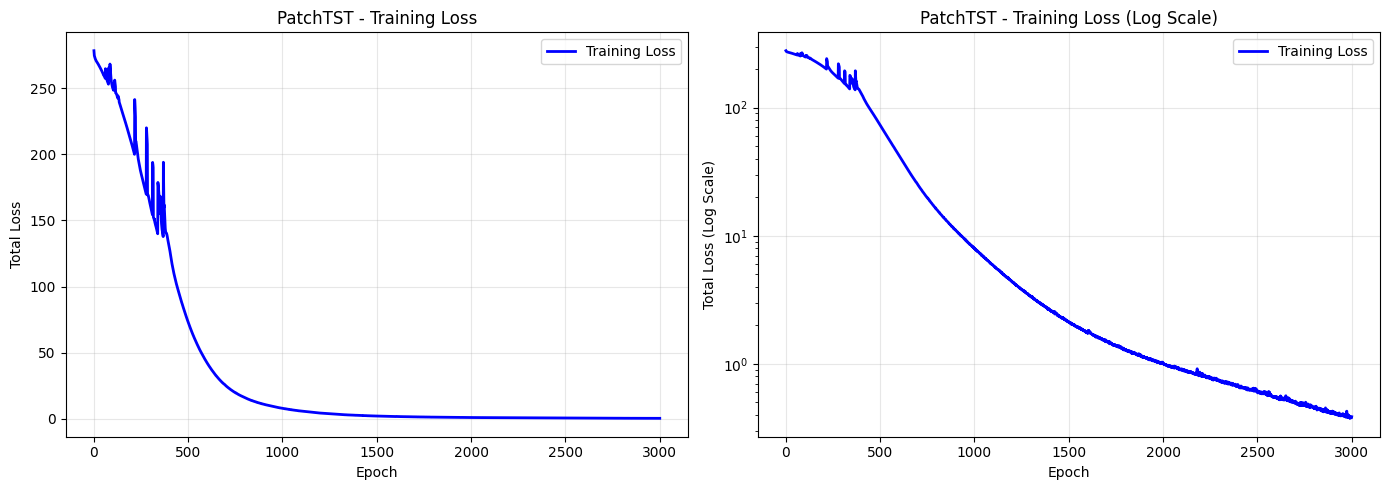

In [25]:
# Tạo trục epochs
epoch_axis = np.arange(1, len(patchtst_original_loss_history) + 1)

# Tạo figure với hai biểu đồ
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ 1: Loss trên thang tuyến tính
axes[0].plot(
    epoch_axis,
    patchtst_original_loss_history,
    color="blue",
    linewidth=2,
    label="Training Loss"
)

axes[0].set_title("PatchTST - Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Total Loss")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Biểu đồ 2: Loss trên thang logarithmic
axes[1].plot(
    epoch_axis,
    patchtst_original_loss_history,
    color="blue",
    linewidth=2,
    label="Training Loss"
)

axes[1].set_yscale("log")
axes[1].set_title("PatchTST - Training Loss (Log Scale)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Total Loss (Log Scale)")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()


PatchTST Predictions vs Ground Truth

Predictions shape: (1845, 5, 3)
Ground Truth shape: (1845, 5, 3)


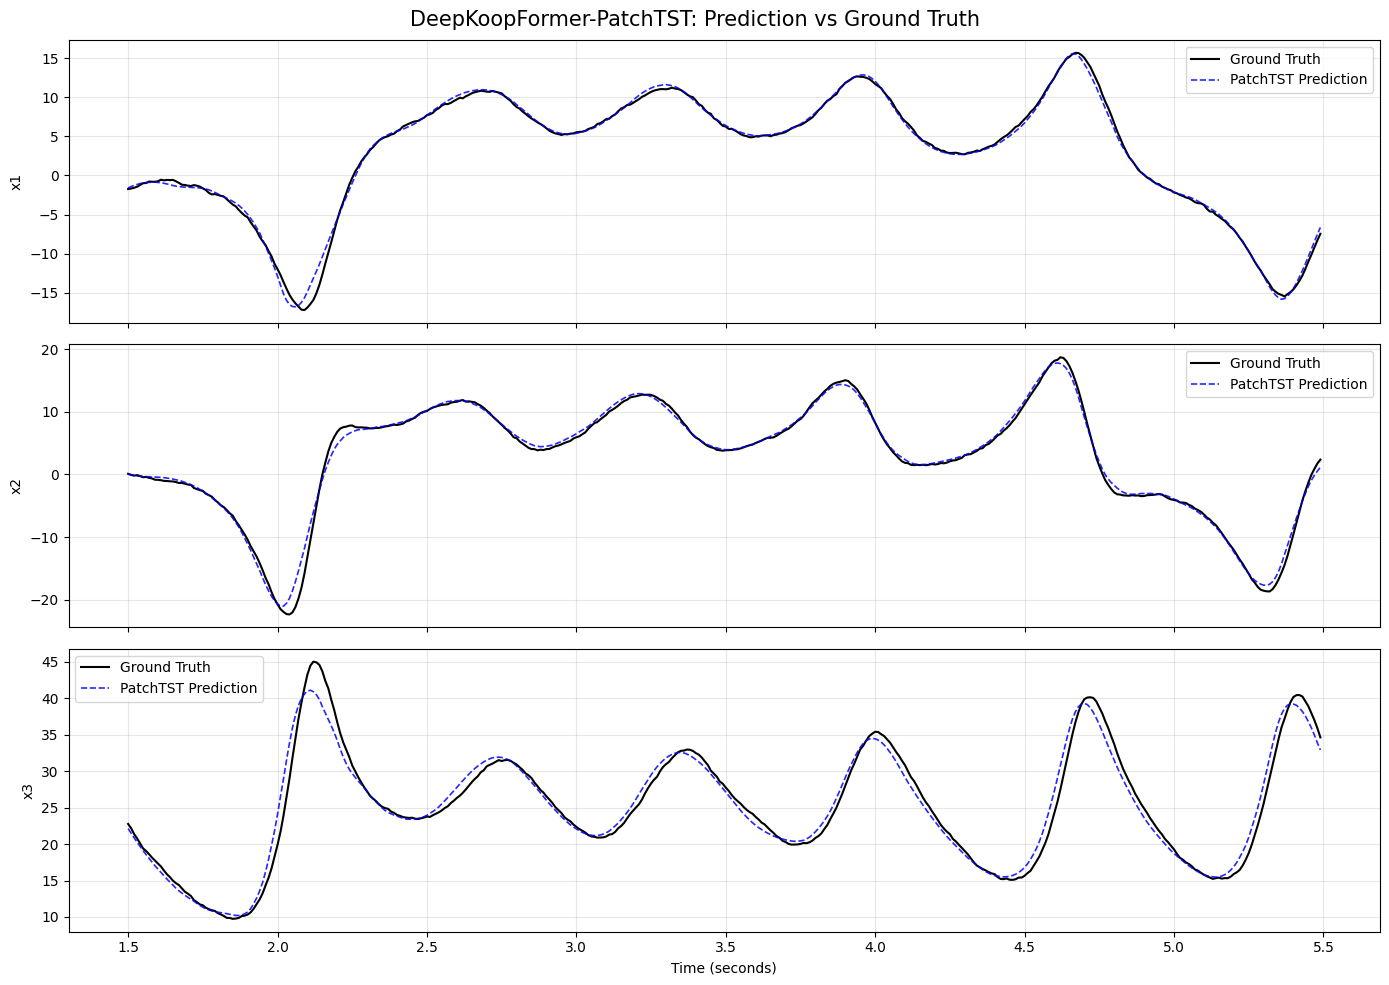


=== In-Sample Forecasting Metrics ===
MAE: 0.509756
RMSE: 0.790329


In [27]:
# 1. Evaluation mode
patchtst_original_model.eval()

# 2. Generate predictions in batches
predictions = []
eval_batch_size = 64

with torch.inference_mode():
    for i in range(0, len(x_in), eval_batch_size):

        x_batch = x_in[i:i + eval_batch_size]

        preds, _, _, _, _ = patchtst_full_model(x_batch)

        predictions.append(preds.cpu())

# 3. Convert predictions and targets to NumPy
y_pred = torch.cat(predictions, dim=0).numpy()
y_true = x_out.detach().cpu().numpy()

# 4. Reshape from (N, 15) to (N, 5, 3)
y_pred = y_pred.reshape(-1, horizon, 3)
y_true = y_true.reshape(-1, horizon, 3)

print("Predictions shape:", y_pred.shape)
print("Ground Truth shape:", y_true.shape)

# 5. Select the first forecast step (t+1)
pred_step1 = y_pred[:, 0, :]
true_step1 = y_true[:, 0, :]

# 6. Select first 400 forecast windows
num_points = 400
dt = 0.01

time_axis = (
    np.arange(len(pred_step1)) + patch_length
) * dt

# 7. Plot predictions vs ground truth
fig, axes = plt.subplots(
    3, 1, figsize=(14, 10), sharex=True
)

for j in range(3):

    axes[j].plot(
        time_axis[:num_points],
        true_step1[:num_points, j],
        color="black",
        linewidth=1.5,
        label="Ground Truth"
    )

    axes[j].plot(
        time_axis[:num_points],
        pred_step1[:num_points, j],
        color="blue",
        linestyle="--",
        linewidth=1.2,
        alpha=0.85,
        label="PatchTST Prediction"
    )

    axes[j].set_ylabel(f"x{j+1}")
    axes[j].grid(True, alpha=0.3)
    axes[j].legend()

axes[-1].set_xlabel("Time (seconds)")

fig.suptitle(
    "DeepKoopFormer-PatchTST: Prediction vs Ground Truth",
    fontsize=15
)

plt.tight_layout()
plt.show()

# 8. Evaluate overall forecasting errors
mae = np.mean(np.abs(y_pred - y_true))
rmse = np.sqrt(np.mean((y_pred - y_true) ** 2))

print("\n=== In-Sample Forecasting Metrics ===")
print(f"MAE: {mae:.6f}")
print(f"RMSE: {rmse:.6f}")


Koopman Operator Stability Evolution

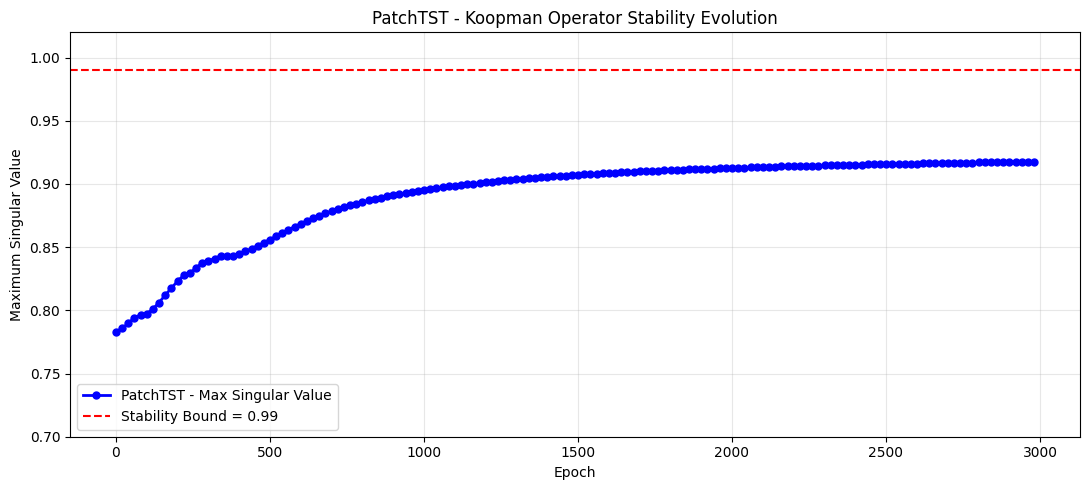


=== Final Koopman Stability ===
Maximum Singular Value: 0.9177458882331848
Spectral Norm: 0.9177468419075012
Spectral Radius: 0.7309206128120422
Stable: True


In [26]:

# 1. Lấy lịch sử singular values
epochs_logged = patchtst_original_singular_epochs

max_singular_values = patchtst_original_singular_history.max(axis=1)

# 2. Vẽ đồ thị
plt.figure(figsize=(11, 5))

plt.plot(
    epochs_logged,
    max_singular_values,
    color="blue",
    marker="o",
    linewidth=2,
    markersize=5,
    label="PatchTST - Max Singular Value"
)

# 3. Giới hạn ổn định
plt.axhline(
    y=0.99,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label="Stability Bound = 0.99"
)

plt.xlabel("Epoch")
plt.ylabel("Maximum Singular Value")
plt.title("PatchTST - Koopman Operator Stability Evolution")

plt.ylim(0.7, 1.02)
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

# 4. Kiểm tra toán tử Koopman sau huấn luyện
patchtst_original_model.eval()

with torch.no_grad():

    z_dummy = torch.zeros((1, 16), device=device)

    _, K_final, S_final = patchtst_original_model.koopman(z_dummy)

    singular_values = torch.linalg.svdvals(K_final)
    eigenvalues = torch.linalg.eigvals(K_final)

    spectral_norm = singular_values.max().item()
    spectral_radius = eigenvalues.abs().max().item()

print("\n=== Final Koopman Stability ===")
print("Maximum Singular Value:", S_final.max().item())
print("Spectral Norm:", spectral_norm)
print("Spectral Radius:", spectral_radius)
print("Stable:", spectral_radius < 1.0)


DeepKoopFormer-Autoformer

In [3]:

torch.manual_seed(42)

if device.type == "cuda":
    torch.cuda.manual_seed_all(42)
    torch.cuda.reset_peak_memory_stats()

# 1. Initialize model
autoformer_original_model = AutoformerWrapper(
    patch_length=patch_length,
    horizon=horizon
).to(device)

# 2. Original optimizer and loss
opt = optim.Adam(autoformer_original_model.parameters(), lr=0.001)
mse = nn.MSELoss()

eig_hist = []
eig_epochs = []
loss_history = []

epochs = 3000

print("=== Original Autoformer Training ===")
print("Training samples:", len(x_in))
print("Batch size:", len(x_in))
print("Epochs:", epochs)
print("Optimizer: Adam")
print("Learning rate: 0.001")
print("Device:", device)

# 3. Original full-batch training loop
for e in range(epochs):

    autoformer_original_model.train()
    opt.zero_grad()

    # Full-batch: all 1845 samples
    preds, latent, latent_next, _, eigvals = autoformer_original_model(x_in)

    # Original loss
    loss = mse(preds, x_out) + 0.1 * torch.relu(
        latent_next.norm(dim=1) ** 2
        - latent.norm(dim=1) ** 2
    ).mean()

    loss.backward()
    opt.step()

    # Additional logging (does not alter training)
    loss_history.append(loss.item())

    if e % 20 == 0:
        eig_hist.append(eigvals.detach().cpu().numpy().copy())
        eig_epochs.append(e + 1)

    if (e + 1) % 100 == 0 or e == 0:
        print(
            f"Epoch [{e+1}/{epochs}] "
            f"Loss: {loss.item():.6f}"
        )

# 4. Original in-sample evaluation
autoformer_original_model.eval()

with torch.no_grad():
    preds, _, _, _, _ = autoformer_original_model(x_in)

autoformer_original_preds = preds.cpu().numpy()
autoformer_original_targets = x_out.cpu().numpy()

autoformer_original_loss_history = np.array(loss_history)
autoformer_original_singular_history = np.array(eig_hist)
autoformer_original_singular_epochs = np.array(eig_epochs)

# 5. Save checkpoint (additional step)
original_checkpoint_path = (
    experiment_dir / "results" / "autoformer_original_fullbatch.pt"
)

torch.save(
    {
        "model_state_dict": autoformer_original_model.state_dict(),
        "loss_history": autoformer_original_loss_history,
        "singular_history": autoformer_original_singular_history,
        "singular_epochs": autoformer_original_singular_epochs,
        "epochs": epochs,
        "batch_size": len(x_in),
        "learning_rate": 0.001
    },
    original_checkpoint_path
)

print("\n=== Final Results ===")
print("Initial Loss:", loss_history[0])
print("Final Loss:", loss_history[-1])
print("Final In-Sample MSE:", mse(preds, x_out).item())
print("Max Singular Value:", eig_hist[-1].max())
print("Checkpoint:", original_checkpoint_path)

if device.type == "cuda":
    print(
        "Peak GPU Memory (MiB):",
        round(torch.cuda.max_memory_allocated() / 1024**2, 2)
    )


=== Original Autoformer Training ===
Training samples: 1845
Batch size: 1845
Epochs: 3000
Optimizer: Adam
Learning rate: 0.001
Device: cuda:0
Epoch [1/3000] Loss: 277.696991
Epoch [100/3000] Loss: 243.754639
Epoch [200/3000] Loss: 199.721390
Epoch [300/3000] Loss: 158.843613
Epoch [400/3000] Loss: 469.767761
Epoch [500/3000] Loss: 106.090912
Epoch [600/3000] Loss: 88.119164
Epoch [700/3000] Loss: 75.571709
Epoch [800/3000] Loss: 72.827309
Epoch [900/3000] Loss: 72.321747
Epoch [1000/3000] Loss: 72.168404
Epoch [1100/3000] Loss: 72.171394
Epoch [1200/3000] Loss: 72.139740
Epoch [1300/3000] Loss: 72.125565
Epoch [1400/3000] Loss: 72.070702
Epoch [1500/3000] Loss: 71.671402
Epoch [1600/3000] Loss: 61.730644
Epoch [1700/3000] Loss: 42.512314
Epoch [1800/3000] Loss: 26.804863
Epoch [1900/3000] Loss: 19.774094
Epoch [2000/3000] Loss: 15.439191
Epoch [2100/3000] Loss: 12.570219
Epoch [2200/3000] Loss: 10.873465
Epoch [2300/3000] Loss: 9.321526
Epoch [2400/3000] Loss: 8.265129
Epoch [2500/3000

In [4]:
# ==== AUTOFORMER TRAIN VS EVAL COMPARISON ====

def calculate_mse(model, training_mode):
    if training_mode:
        model.train()
    else:
        model.eval()

    total_squared_error = 0.0
    total_elements = 0

    with torch.no_grad():
        for start in range(0, len(x_in), 64):
            x_batch = x_in[start:start + 64]
            y_batch = x_out[start:start + 64]

            preds, _, _, _, _ = model(x_batch)

            total_squared_error += (
                (preds - y_batch) ** 2
            ).sum().item()

            total_elements += y_batch.numel()

    return total_squared_error / total_elements


train_mode_mse = calculate_mse(
    autoformer_original_model, training_mode=True
)

eval_mode_mse = calculate_mse(
    autoformer_original_model, training_mode=False
)

print("=== AUTOFORMER MSE COMPARISON ===")
print("Final Training Loss:", loss_history[-1])
print("MSE in Train Mode:", train_mode_mse)
print("MSE in Eval Mode:", eval_mode_mse)


=== AUTOFORMER MSE COMPARISON ===
Final Training Loss: 3.9280176162719727
MSE in Train Mode: 3.9763680652594284
MSE in Eval Mode: 12.407234925474254


In [5]:

# ==== DROPOUT EFFECT ANALYSIS ====

model = autoformer_original_model

# Lưu xác suất Dropout hiện tại
dropout_layers = [
    m for m in model.modules()
    if isinstance(m, nn.Dropout)
]

attention_layers = [
    m for m in model.modules()
    if isinstance(m, nn.MultiheadAttention)
]

original_dropout = [m.p for m in dropout_layers]
original_attention_dropout = [m.dropout for m in attention_layers]

# Tắt toàn bộ Dropout nhưng vẫn giữ Training Mode
try:
    for m in dropout_layers:
        m.p = 0.0

    for m in attention_layers:
        m.dropout = 0.0

    train_no_dropout_mse = calculate_mse(
        model,
        training_mode=True
    )

finally:
    # Khôi phục Dropout ban đầu
    for m, p in zip(dropout_layers, original_dropout):
        m.p = p

    for m, p in zip(attention_layers, original_attention_dropout):
        m.dropout = p

    model.eval()

print("=== DROPOUT ANALYSIS ===")
print("Train Mode (Dropout ON):", train_mode_mse)
print("Train Mode (Dropout OFF):", train_no_dropout_mse)
print("Eval Mode (Dropout OFF):", eval_mode_mse)


=== DROPOUT ANALYSIS ===
Train Mode (Dropout ON): 3.9763680652594284
Train Mode (Dropout OFF): 12.407234925474254
Eval Mode (Dropout OFF): 12.407234925474254


Informer Full-batch Training

In [3]:
torch.manual_seed(42)

if device.type == "cuda":
    torch.cuda.manual_seed_all(42)
    torch.cuda.reset_peak_memory_stats()

# 1. Initialize model
informer_original_model = InformerWrapper(
    patch_length=patch_length,
    horizon=horizon
).to(device)

# 2. Original optimizer and loss
opt = optim.Adam(informer_original_model.parameters(), lr=0.001)
mse = nn.MSELoss()

eig_hist = []
eig_epochs = []
loss_history = []

epochs = 3000

print("=== Original Informer Training ===")
print("Training samples:", len(x_in))
print("Batch size:", len(x_in))
print("Epochs:", epochs)
print("Optimizer: Adam")
print("Learning rate: 0.001")
print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(device))

# 3. Original full-batch training loop
for e in range(epochs):

    informer_original_model.train()
    opt.zero_grad()

    # Full-batch: all 1845 samples
    preds, latent, latent_next, _, eigvals = informer_original_model(x_in)

    # Original loss
    loss = mse(preds, x_out) + 0.1 * torch.relu(
        latent_next.norm(dim=1) ** 2
        - latent.norm(dim=1) ** 2
    ).mean()

    loss.backward()
    opt.step()

    # Additional logging (does not alter training)
    loss_history.append(loss.item())

    if e % 20 == 0:
        eig_hist.append(eigvals.detach().cpu().numpy().copy())
        eig_epochs.append(e + 1)

    if (e + 1) % 100 == 0 or e == 0:
        print(
            f"Epoch [{e+1}/{epochs}] "
            f"Loss: {loss.item():.6f}"
        )

# 4. Save checkpoint
informer_original_loss_history = np.array(loss_history)
informer_original_singular_history = np.array(eig_hist)
informer_original_singular_epochs = np.array(eig_epochs)

original_checkpoint_path = (
    experiment_dir / "results" / "informer_original_fullbatch.pt"
)

torch.save(
    {
        "model_state_dict": informer_original_model.state_dict(),
        "loss_history": informer_original_loss_history,
        "singular_history": informer_original_singular_history,
        "singular_epochs": informer_original_singular_epochs,
        "epochs": epochs,
        "batch_size": len(x_in),
        "learning_rate": 0.001
    },
    original_checkpoint_path
)

# 5. Original in-sample evaluation
informer_original_model.eval()

with torch.no_grad():
    preds, _, _, _, _ = informer_original_model(x_in)

    _, _, final_singular_values = informer_original_model.koopman(
        torch.zeros(1, 16, device=device)
    )

informer_original_preds = preds.cpu().numpy()
informer_original_targets = x_out.cpu().numpy()

print("\n=== Final Results ===")
print("Initial Loss:", loss_history[0])
print("Final Loss:", loss_history[-1])
print("Final In-Sample MSE:", mse(preds, x_out).item())
print("Max Singular Value:", final_singular_values.max().item())
print("Checkpoint:", original_checkpoint_path)

if device.type == "cuda":
    print(
        "Peak GPU Memory (MiB):",
        round(torch.cuda.max_memory_allocated() / 1024**2, 2)
    )


=== Original Informer Training ===
Training samples: 1845
Batch size: 1845
Epochs: 3000
Optimizer: Adam
Learning rate: 0.001
Device: cuda
GPU: Quadro T1000
Epoch [1/3000] Loss: 282.345551
Epoch [100/3000] Loss: 244.040787
Epoch [200/3000] Loss: 203.136108
Epoch [300/3000] Loss: 157.021164
Epoch [400/3000] Loss: 106.965912
Epoch [500/3000] Loss: 60.992970
Epoch [600/3000] Loss: 41.711239
Epoch [700/3000] Loss: 30.417049
Epoch [800/3000] Loss: 28.009262
Epoch [900/3000] Loss: 27.304628
Epoch [1000/3000] Loss: 16.992786
Epoch [1100/3000] Loss: 10.876915
Epoch [1200/3000] Loss: 7.746890
Epoch [1300/3000] Loss: 6.331288
Epoch [1400/3000] Loss: 5.502367
Epoch [1500/3000] Loss: 4.838574
Epoch [1600/3000] Loss: 3.814125
Epoch [1700/3000] Loss: 2.589435
Epoch [1800/3000] Loss: 1.866870
Epoch [1900/3000] Loss: 1.529378
Epoch [2000/3000] Loss: 50.361977
Epoch [2100/3000] Loss: 37.136913
Epoch [2200/3000] Loss: 25.940798
Epoch [2300/3000] Loss: 11.282610
Epoch [2400/3000] Loss: 3.985792
Epoch [250

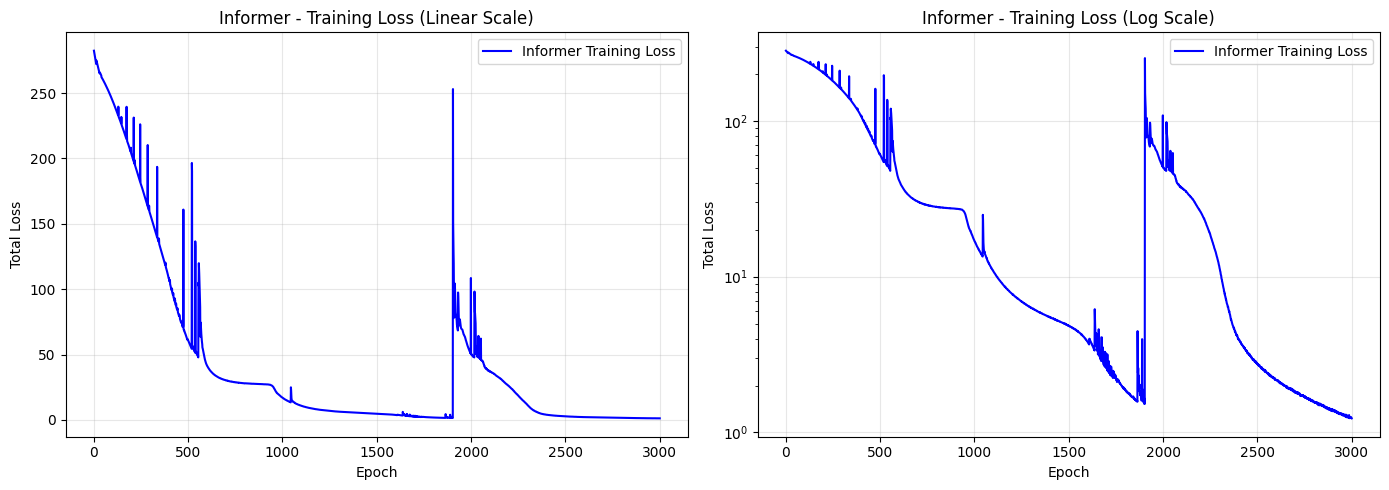

=== Informer Full-batch Training ===
Total Epochs: 3000
Initial Loss: 282.3455505371094
Final Loss: 1.2312705516815186
Minimum Loss: 1.2312705516815186
Best Epoch: 3000


In [4]:

# Cell 13 - Informer Training Loss Visualization

# 1. Load training history
checkpoint_path = (
    experiment_dir / "results" / "informer_original_fullbatch.pt"
)

checkpoint = torch.load(checkpoint_path, map_location="cpu")

loss_history = np.asarray(checkpoint["loss_history"])
epoch_axis = np.arange(1, len(loss_history) + 1)

# 2. Plot training loss
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Linear scale
axes[0].plot(
    epoch_axis,
    loss_history,
    color="blue",
    linewidth=1.5,
    label="Informer Training Loss"
)

axes[0].set_title("Informer - Training Loss (Linear Scale)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Total Loss")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Logarithmic scale
axes[1].plot(
    epoch_axis,
    loss_history,
    color="blue",
    linewidth=1.5,
    label="Informer Training Loss"
)

axes[1].set_yscale("log")
axes[1].set_title("Informer - Training Loss (Log Scale)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Total Loss")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

# 3. Training summary
print("=== Informer Full-batch Training ===")
print("Total Epochs:", len(loss_history))
print("Initial Loss:", loss_history[0])
print("Final Loss:", loss_history[-1])
print("Minimum Loss:", loss_history.min())
print("Best Epoch:", loss_history.argmin() + 1)


Lorenz Ground Truth vs Predictions

PatchTST In-Sample MSE: 0.281637
Autoformer In-Sample MSE: 12.407236
Informer In-Sample MSE: 1.451354


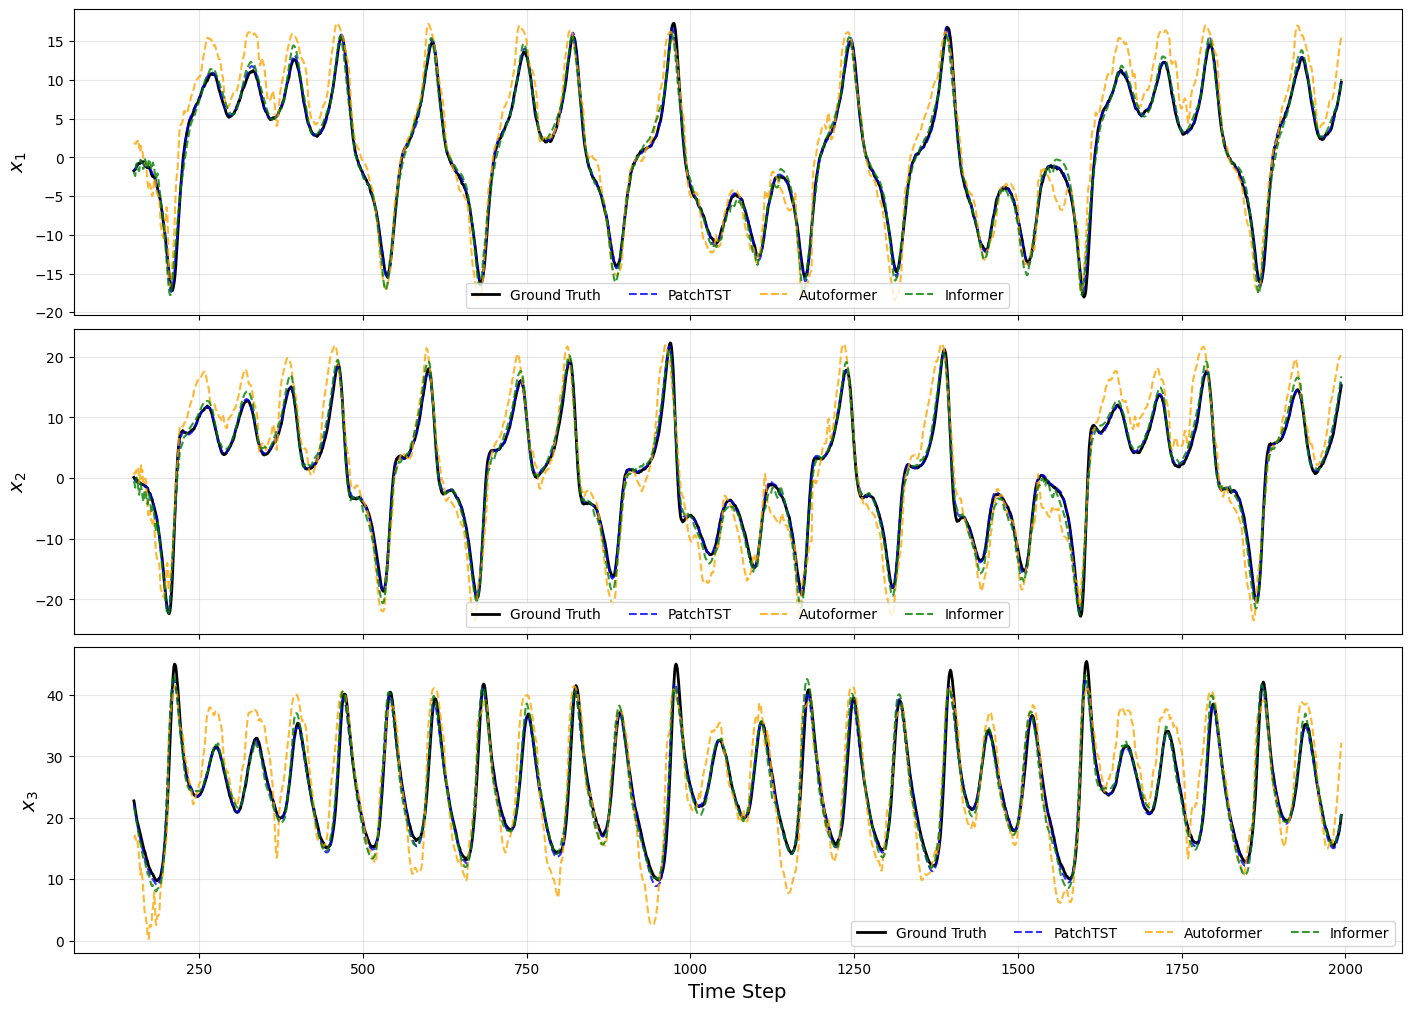

In [2]:
# 1. Load checkpoints
checkpoint_paths = {
    "PatchTST": experiment_dir / "results" / "patchtst_original_fullbatch.pt",
    "Autoformer": experiment_dir / "results" / "autoformer_original_fullbatch (1).pt",
    "Informer": experiment_dir / "results" / "informer_original_fullbatch.pt"
}

models = {
    "PatchTST": PatchTSTWrapper(patch_length, horizon).to(device),
    "Autoformer": AutoformerWrapper(patch_length, horizon).to(device),
    "Informer": InformerWrapper(patch_length, horizon).to(device)
}

results = {}

# 2. Load models and evaluate
for name, model in models.items():
    checkpoint = torch.load(
        checkpoint_paths[name],
        map_location="cpu"
    )

    if name == "Autoformer":
        assert checkpoint.get("batch_size") == len(x_in), (
            "Checkpoint Autoformer không phải bản Full-batch trực tiếp"
        )

    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    predictions = []

    with torch.no_grad():
        for start in range(0, len(x_in), 64):
            preds, _, _, _, _ = model(x_in[start:start + 64])
            predictions.append(preds.cpu())

    predictions = torch.cat(predictions, dim=0).numpy()
    results[name] = predictions

    mse_value = np.mean(
        (predictions - x_out.cpu().numpy()) ** 2
    )

    print(f"{name} In-Sample MSE: {mse_value:.6f}")

# 3. Plot predictions
true_vals = x_out.cpu().numpy()

num_points = len(x_in)
time_steps = np.arange(num_points) + patch_length
var_labels = [r"$x_1$", r"$x_2$", r"$x_3$"]

colors = {
    "PatchTST": "blue",
    "Autoformer": "orange",
    "Informer": "green"
}

fig, axes = plt.subplots(
    3, 1, figsize=(14, 10),
    sharex=True,
    constrained_layout=True
)

for idx, ax in enumerate(axes):

    ax.plot(
        time_steps,
        true_vals[:num_points, idx],
        color="black",
        linewidth=2,
        label="Ground Truth"
    )

    for name, preds in results.items():
        ax.plot(
            time_steps,
            preds[:num_points, idx],
            "--",
            color=colors[name],
            linewidth=1.5,
            alpha=0.8,
            label=name
        )

    ax.set_ylabel(var_labels[idx], fontsize=14)
    ax.grid(True, alpha=0.3)
    ax.legend(ncol=4, fontsize=10)

axes[-1].set_xlabel("Time Step", fontsize=14)

plt.show()


PatchTST: Final Max Singular Value = 0.917746
Autoformer: Final Max Singular Value = 0.892004
Informer: Final Max Singular Value = 0.961025


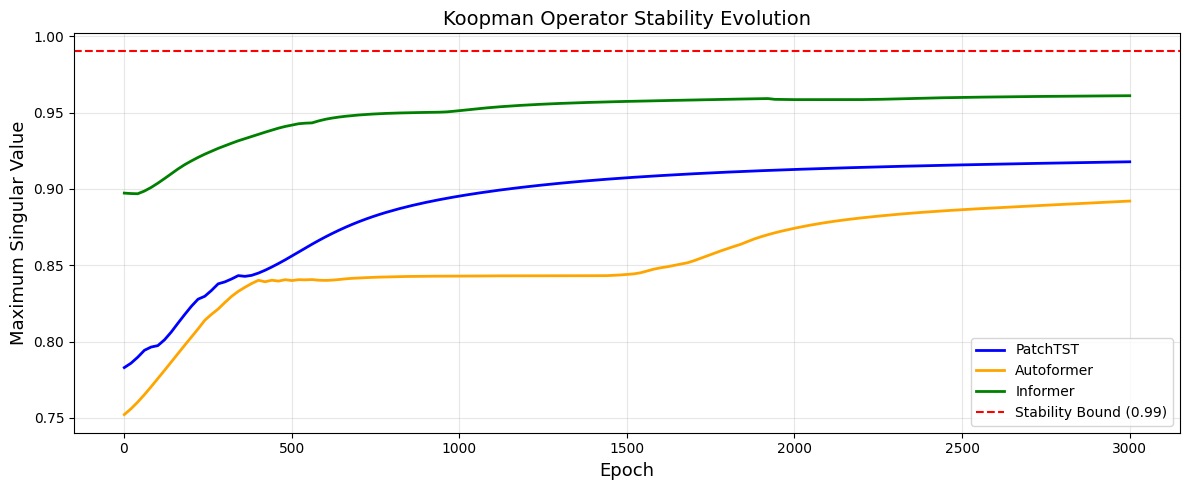

In [3]:

# Cell 15 - Koopman Operator Stability Evolution

colors = {
    "PatchTST": "blue",
    "Autoformer": "orange",
    "Informer": "green"
}

plt.figure(figsize=(12, 5))

# 1. Load singular value histories
for name, path in checkpoint_paths.items():

    checkpoint = torch.load(path, map_location="cpu")

    singular_history = np.asarray(
        checkpoint["singular_history"]
    )

    singular_epochs = np.asarray(
        checkpoint["singular_epochs"]
    )

    max_singular = singular_history.max(axis=1)

    # Giá trị kỳ dị cuối cùng sau epoch 3000
    final_singular = (
        torch.sigmoid(
            checkpoint["model_state_dict"]["koopman.S_unconstrained"]
        ) * 0.99
    ).max().item()

    plot_epochs = np.append(singular_epochs, 3000)
    plot_values = np.append(max_singular, final_singular)

    plt.plot(
        plot_epochs,
        plot_values,
        label=name,
        color=colors[name],
        linewidth=2
    )

    print(
        f"{name}: Final Max Singular Value = "
        f"{final_singular:.6f}"
    )

# 2. Stability bound
plt.axhline(
    y=0.99,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label="Stability Bound (0.99)"
)

# 3. Plot
plt.xlabel("Epoch", fontsize=13)
plt.ylabel("Maximum Singular Value", fontsize=13)
plt.title("Koopman Operator Stability Evolution", fontsize=14)

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
